In [1]:
import pandas as pd

# Load IPL datasets
batting = pd.read_csv("/content/batting_stats.csv")
bowling = pd.read_csv("/content/bowling_stats.csv")
deliveries = pd.read_csv("/content/deliveries.csv")
fielding = pd.read_csv("/content/fielding_stats.csv")
matches = pd.read_csv("/content/matches.csv")
points_table = pd.read_csv("/content/points_table.csv")
squads = pd.read_csv("/content/squads.csv")
venues = pd.read_csv("/content/venues.csv")

print("All IPL datasets loaded successfully!")

All IPL datasets loaded successfully!


In [2]:
datasets = {
    "Batting": batting,
    "Bowling": bowling,
    "Deliveries": deliveries,
    "Fielding": fielding,
    "Matches": matches,
    "Points Table": points_table,
    "Squads": squads,
    "Venues": venues
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows × {df.shape[1]} columns")

Batting: 15 rows × 17 columns
Bowling: 15 rows × 17 columns
Deliveries: 17477 rows × 19 columns
Fielding: 15 rows × 6 columns
Matches: 39 rows × 23 columns
Points Table: 10 rows × 9 columns
Squads: 257 rows × 6 columns
Venues: 12 rows × 5 columns


In [3]:
for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(name.upper())
    print("=" * 60)
    print("Columns:")
    print(df.columns.tolist())


BATTING
Columns:
['position', 'batsman', 'team', 'matches', 'innings', 'runs', 'impact', 'average', 'strike_rate', 'not_outs', 'high_score', 'balls_faced', 'hundreds', 'fifties', 'ducks', 'fours', 'sixes']

BOWLING
Columns:
['position', 'bowler', 'team', 'matches', 'innings', 'wickets', 'economy', 'impact', 'bbi', 'overs', 'balls', 'dot_balls', 'maiden_overs', 'runs', 'avg', '4wh', '5wh']

DELIVERIES
Columns:
['match_no', 'date', 'stage', 'venue', 'batting_team', 'bowling_team', 'innings', 'over', 'striker', 'bowler', 'runs_of_bat', 'extras', 'wide', 'legbyes', 'byes', 'noballs', 'wicket_type', 'player_dismissed', 'fielder']

FIELDING
Columns:
['rank', 'player', 'team', 'matches', 'catches', 'cpm']

MATCHES
Columns:
['match_id', 'date', 'venue', 'team1', 'team2', 'stage', 'toss_winner', 'toss_decision', 'first_ings_score', 'first_ings_wkts', 'second_ings_score', 'second_ings_wkts', 'match_result', 'match_winner', 'wb_runs', 'wb_wickets', 'balls_left', 'player_of_the_match', 'top_score

In [4]:
for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(name.upper())
    print("=" * 60)

    print("Missing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())


BATTING
Missing values:
position       0
batsman        0
team           0
matches        0
innings        0
runs           0
impact         0
average        0
strike_rate    0
not_outs       0
high_score     0
balls_faced    0
hundreds       0
fifties        0
ducks          0
fours          0
sixes          0
dtype: int64

Duplicate rows: 0

BOWLING
Missing values:
position        0
bowler          0
team            0
matches         0
innings         0
wickets         0
economy         0
impact          0
bbi             0
overs           0
balls           0
dot_balls       0
maiden_overs    0
runs            0
avg             0
4wh             0
5wh             0
dtype: int64

Duplicate rows: 0

DELIVERIES
Missing values:
match_no                0
date                    0
stage                   0
venue                   0
batting_team            0
bowling_team            0
innings                 0
over                    0
striker                 0
bowler                  0
run

In [5]:
print("MATCH DATE RANGE")
print("=" * 40)

match_dates = pd.to_datetime(matches["date"])

print("Start date:", match_dates.min())
print("End date:", match_dates.max())

print("\nUnique years:")
print(sorted(match_dates.dt.year.unique()))

print("\nMatches by year:")
print(match_dates.dt.year.value_counts().sort_index())

MATCH DATE RANGE
Start date: 2026-03-28 00:00:00
End date: 2026-04-27 00:00:00

Unique years:
[np.int32(2026)]

Matches by year:
date
2026    39
Name: count, dtype: int64


In [6]:
top_scorers = (
    batting[
        ["batsman", "team", "matches", "innings",
         "runs", "average", "strike_rate", "balls_faced"]
    ]
    .sort_values("runs", ascending=False)
    .reset_index(drop=True)
)

print("TOP RUN SCORERS")
print("=" * 70)

display(top_scorers.head(10))

TOP RUN SCORERS


,batsman,team,matches,innings,runs,average,strike_rate,balls_faced
0,Abhishek Sharma,SRH,8,8,380,54.28,212.29,179
1,KL Rahul,DC,8,8,358,51.14,185.49,193
2,Vaibhav Sooryavanshi,RR,8,8,357,44.62,234.86,152
3,Virat Kohli,RCB,8,8,351,58.50,162.50,216
4,Heinrich Klaasen,SRH,8,8,349,49.85,149.78,233
5,Shubman Gill,GT,7,7,330,47.14,148.64,222
6,Sai Sudarshan,GT,8,8,322,40.25,163.45,197
7,Ishan Kishan,SRH,8,8,312,39.00,198.72,157
8,Sanju Samson,CSK,8,8,304,50.66,169.83,179
9,Prabhsimran Singh,PBKS,7,6,287,57.40,192.61,149


In [7]:
top_strike_rate = (
    batting[
        ["batsman", "team", "matches", "innings",
         "runs", "balls_faced", "strike_rate"]
    ]
    .sort_values("strike_rate", ascending=False)
    .reset_index(drop=True)
)

print("TOP STRIKE RATES")
print("=" * 70)

display(top_strike_rate.head(10))

TOP STRIKE RATES


,batsman,team,matches,innings,runs,balls_faced,strike_rate
0,Priyansh Arya,PBKS,6,6,254,102,249.01
1,Vaibhav Sooryavanshi,RR,8,8,357,152,234.86
2,Abhishek Sharma,SRH,8,8,380,179,212.29
3,Ishan Kishan,SRH,8,8,312,157,198.72
4,Prabhsimran Singh,PBKS,7,6,287,149,192.61
5,Devdutt Padikkal,RCB,8,7,242,126,192.06
6,Shreyas Iyer,PBKS,7,6,279,150,186.00
7,KL Rahul,DC,8,8,358,193,185.49
8,Sanju Samson,CSK,8,8,304,179,169.83
9,Sai Sudarshan,GT,8,8,322,197,163.45


In [8]:
team_win_rate = points_table.copy()

team_win_rate["win_rate_%"] = (
    team_win_rate["wins"] / team_win_rate["matches"] * 100
).round(2)

team_win_rate = (
    team_win_rate[
        ["position", "team", "matches", "wins", "defeats",
         "ties", "abandoned", "points", "nrr", "win_rate_%"]
    ]
    .sort_values("win_rate_%", ascending=False)
    .reset_index(drop=True)
)

print("TEAM WIN RATE")
print("=" * 70)

display(team_win_rate)

TEAM WIN RATE


,position,team,matches,wins,defeats,ties,abandoned,points,nrr,win_rate_%
0,1,Punjab Kings,7,6,0,0,1,13,1.333,85.71
1,2,Royal Challengers Bengaluru,8,6,2,0,0,12,1.919,75.00
2,3,Sunrisers Hyderabad,8,5,3,0,0,10,0.815,62.50
3,4,Rajasthan Royals,8,5,3,0,0,10,0.602,62.50
4,5,Gujarat Titans,8,4,4,0,0,8,-0.475,50.00
5,6,Chennai Super Kings,8,3,5,0,0,6,-0.121,37.50
6,7,Delhi Capitals,8,3,5,0,0,6,-1.060,37.50
7,9,Mumbai Indians,7,2,5,0,0,4,-0.736,28.57
8,8,Kolkata Knight Riders,8,2,5,0,1,5,0.751,25.00
9,10,Lucknow Super Giants,8,2,6,0,0,4,-1.106,25.00


In [9]:
player_performance = batting[
    [
        "batsman",
        "team",
        "matches",
        "innings",
        "runs",
        "average",
        "strike_rate",
        "balls_faced",
        "fours",
        "sixes"
    ]
].copy()

player_performance = (
    player_performance
    .sort_values(
        ["runs", "strike_rate"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

print("PLAYER PERFORMANCE ANALYSIS")
print("=" * 80)

display(player_performance)

PLAYER PERFORMANCE ANALYSIS


,batsman,team,matches,innings,runs,average,strike_rate,balls_faced,fours,sixes
0,Abhishek Sharma,SRH,8,8,380,54.28,212.29,179,36,28
1,KL Rahul,DC,8,8,358,51.14,185.49,193,36,19
2,Vaibhav Sooryavanshi,RR,8,8,357,44.62,234.86,152,31,32
3,Virat Kohli,RCB,8,8,351,58.50,162.50,216,37,14
4,Heinrich Klaasen,SRH,8,8,349,49.85,149.78,233,25,14
5,Shubman Gill,GT,7,7,330,47.14,148.64,222,30,14
6,Sai Sudarshan,GT,8,8,322,40.25,163.45,197,32,17
7,Ishan Kishan,SRH,8,8,312,39.00,198.72,157,35,16
8,Sanju Samson,CSK,8,8,304,50.66,169.83,179,33,15
9,Prabhsimran Singh,PBKS,7,6,287,57.40,192.61,149,31,16


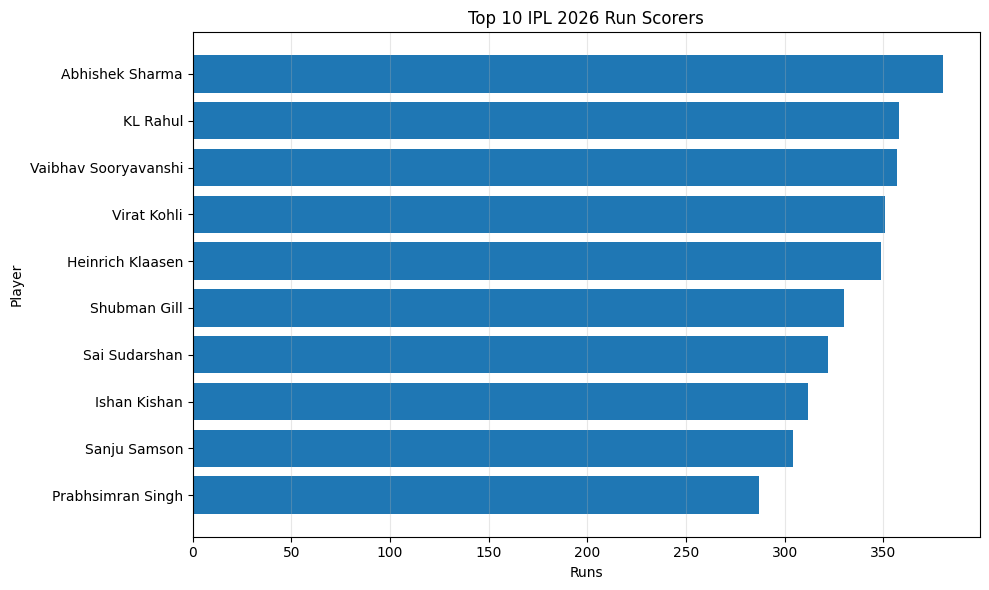

In [10]:
import matplotlib.pyplot as plt

top_10_runs = player_performance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_runs["batsman"][::-1],
    top_10_runs["runs"][::-1]
)

plt.xlabel("Runs")
plt.ylabel("Player")
plt.title("Top 10 IPL 2026 Run Scorers")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig("top_10_run_scorers.png", dpi=300, bbox_inches="tight")

plt.show()

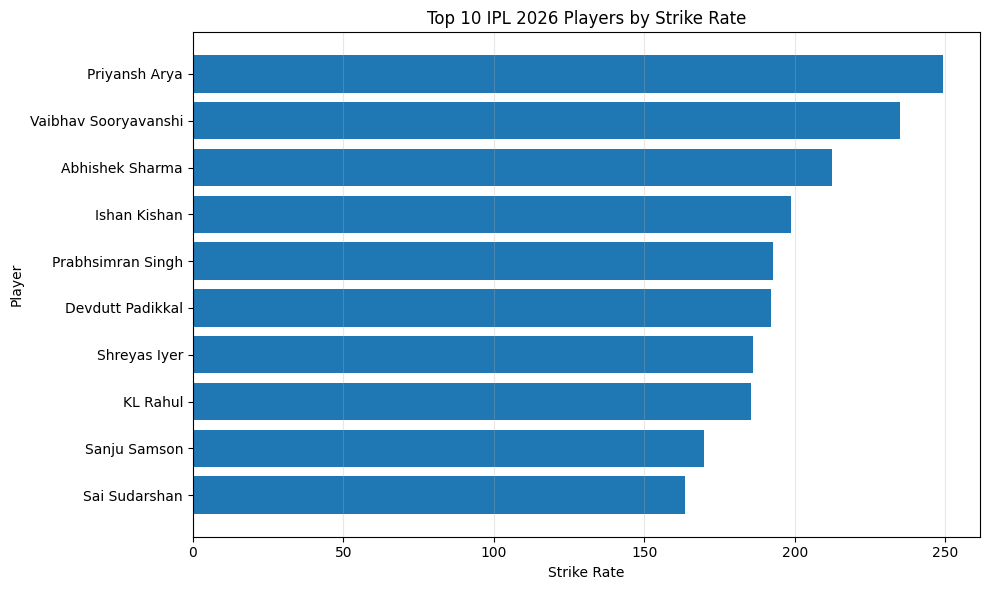

In [11]:
top_10_strike_rate = (
    batting[
        ["batsman", "team", "runs", "balls_faced", "strike_rate"]
    ]
    .sort_values("strike_rate", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_strike_rate["batsman"][::-1],
    top_10_strike_rate["strike_rate"][::-1]
)

plt.xlabel("Strike Rate")
plt.ylabel("Player")
plt.title("Top 10 IPL 2026 Players by Strike Rate")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig("top_10_strike_rate.png", dpi=300, bbox_inches="tight")

plt.show()

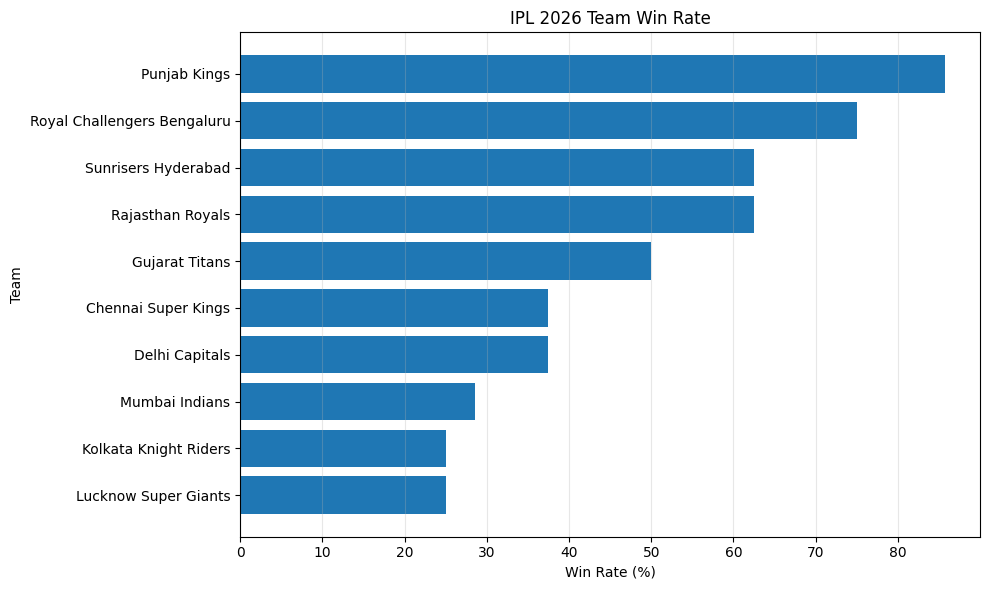

In [12]:
plt.figure(figsize=(10, 6))

plt.barh(
    team_win_rate["team"][::-1],
    team_win_rate["win_rate_%"][::-1]
)

plt.xlabel("Win Rate (%)")
plt.ylabel("Team")
plt.title("IPL 2026 Team Win Rate")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig("team_win_rate.png", dpi=300, bbox_inches="tight")

plt.show()

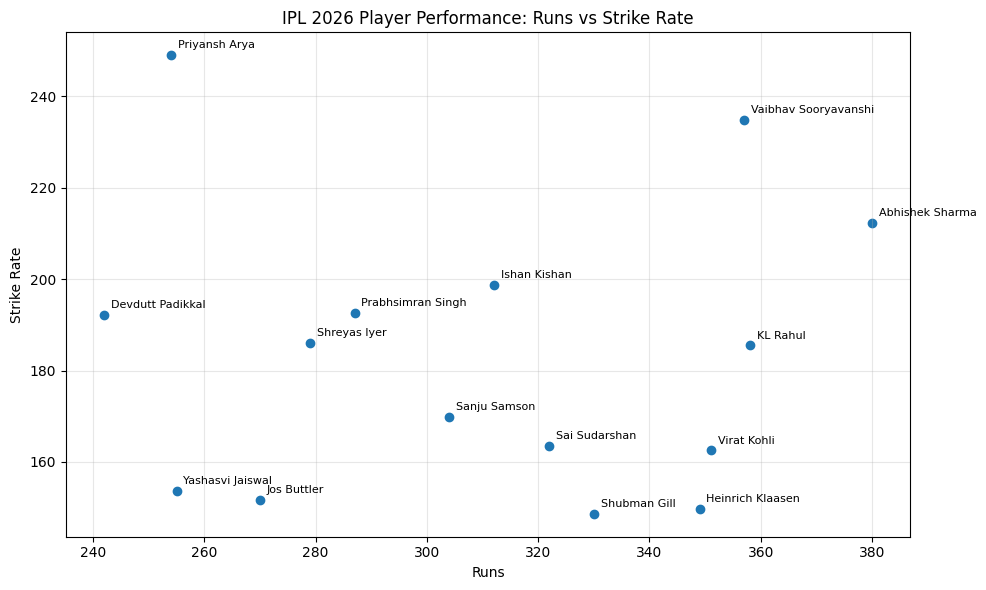

In [13]:
plt.figure(figsize=(10, 6))

plt.scatter(
    player_performance["runs"],
    player_performance["strike_rate"]
)

# Add player names
for _, row in player_performance.iterrows():
    plt.annotate(
        row["batsman"],
        (row["runs"], row["strike_rate"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Runs")
plt.ylabel("Strike Rate")
plt.title("IPL 2026 Player Performance: Runs vs Strike Rate")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "player_performance_runs_vs_strike_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
# Identify key results
top_run_scorer = batting.loc[batting["runs"].idxmax()]
top_strike_rate_player = batting.loc[batting["strike_rate"].idxmax()]
top_win_rate_team = team_win_rate.iloc[0]

# Create insights
insights = f"""
IPL 2026 SPORTS DATA ANALYSIS – KEY INSIGHTS
=============================================

1. Dataset Overview
The supplied dataset contains IPL 2026 match and player information.
The match data covers {len(matches)} matches from
{match_dates.min().strftime("%d %B %Y")} to
{match_dates.max().strftime("%d %B %Y")}.

2. Top Run Scorer
{top_run_scorer["batsman"]} recorded the highest runs with
{top_run_scorer["runs"]} runs for {top_run_scorer["team"]}.

3. Highest Strike Rate
{top_strike_rate_player["batsman"]} recorded the highest strike rate
of {top_strike_rate_player["strike_rate"]:.2f}, with
{top_strike_rate_player["runs"]} runs from
{top_strike_rate_player["balls_faced"]} balls.

4. Team Win Rate
{top_win_rate_team["team"]} recorded the highest calculated win rate
of {top_win_rate_team["win_rate_%"]:.2f}% in the supplied points table.

5. Player Performance
Player performance was analyzed using runs, batting average,
strike rate, balls faced, fours, and sixes.

6. Season Analysis
The supplied match data contains only the 2026 IPL season.
Therefore, a cross-season player performance comparison could not
be performed from this dataset.

7. Business / Sports Insight
Runs, strike rate, and team win rate provide different perspectives
of performance. Combining these metrics gives a broader view of
individual player contribution and team performance.

"""

print(insights)

# Save insights
with open("ipl_analysis_insights.txt", "w", encoding="utf-8") as file:
    file.write(insights)

print("\nInsights saved successfully as: ipl_analysis_insights.txt")


IPL 2026 SPORTS DATA ANALYSIS – KEY INSIGHTS

1. Dataset Overview
The supplied dataset contains IPL 2026 match and player information.
The match data covers 39 matches from
28 March 2026 to
27 April 2026.

2. Top Run Scorer
Abhishek Sharma recorded the highest runs with
380 runs for SRH.

3. Highest Strike Rate
Priyansh Arya recorded the highest strike rate
of 249.01, with
254 runs from
102 balls.

4. Team Win Rate
Punjab Kings recorded the highest calculated win rate
of 85.71% in the supplied points table.

5. Player Performance
Player performance was analyzed using runs, batting average,
strike rate, balls faced, fours, and sixes.

6. Season Analysis
The supplied match data contains only the 2026 IPL season.
Therefore, a cross-season player performance comparison could not
be performed from this dataset.

7. Business / Sports Insight
Runs, strike rate, and team win rate provide different perspectives
of performance. Combining these metrics gives a broader view of
individual player c

In [15]:
# Export analysis results

top_scorers.to_csv("top_10_run_scorers.csv", index=False)

top_strike_rate.to_csv("top_10_strike_rate.csv", index=False)

team_win_rate.to_csv("team_win_rate_analysis.csv", index=False)

player_performance.to_csv("player_performance_analysis.csv", index=False)

print("CSV files exported successfully!")
print()
print("1. top_10_run_scorers.csv")
print("2. top_10_strike_rate.csv")
print("3. team_win_rate_analysis.csv")
print("4. player_performance_analysis.csv")

CSV files exported successfully!

1. top_10_run_scorers.csv
2. top_10_strike_rate.csv
3. team_win_rate_analysis.csv
4. player_performance_analysis.csv


In [16]:
# Create final KPI summary

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Matches",
        "Dataset Year",
        "Top Run Scorer",
        "Top Run Scorer Runs",
        "Highest Strike Rate Player",
        "Highest Strike Rate",
        "Highest Win Rate Team",
        "Highest Team Win Rate"
    ],
    "Value": [
        len(matches),
        match_dates.dt.year.min(),
        top_run_scorer["batsman"],
        top_run_scorer["runs"],
        top_strike_rate_player["batsman"],
        top_strike_rate_player["strike_rate"],
        top_win_rate_team["team"],
        top_win_rate_team["win_rate_%"]
    ]
})

display(kpi_summary)

kpi_summary.to_csv(
    "ipl_analysis_kpi_summary.csv",
    index=False
)

print("\nKPI summary saved successfully as: ipl_analysis_kpi_summary.csv")

,Metric,Value
0,Total Matches,39
1,Dataset Year,2026
2,Top Run Scorer,Abhishek Sharma
3,Top Run Scorer Runs,380
4,Highest Strike Rate Player,Priyansh Arya
5,Highest Strike Rate,249.01
6,Highest Win Rate Team,Punjab Kings
7,Highest Team Win Rate,85.71



KPI summary saved successfully as: ipl_analysis_kpi_summary.csv


In [17]:
final_summary = """
IPL SPORTS DATA ANALYSIS – PROJECT SUMMARY
===========================================

PROJECT: IPL 2026 Sports Data Analysis

DATASET
-------
The supplied dataset contains IPL 2026 match and player data.
The match data covers 39 matches from 28 March 2026 to
27 April 2026.

ANALYSIS COMPLETED
------------------
1. Data quality check
2. Top run scorer analysis
3. Strike rate analysis
4. Team win rate analysis
5. Player performance analysis
6. Runs vs strike rate comparison
7. Team win rate visualization
8. Top 10 run scorers visualization
9. Top 10 strike rate visualization
10. KPI summary
11. Short business/sports insights

KEY RESULTS
-----------
Top Run Scorer: Abhishek Sharma
Runs: 380

Highest Strike Rate Player: Priyansh Arya
Strike Rate: 249.01

Highest Team Win Rate: Punjab Kings
Win Rate: 85.71%

DATASET LIMITATION
------------------
The supplied match data contains only the 2026 IPL season.
Therefore, cross-season player performance comparison could not
be performed from this dataset.

OUTPUTS
-------
Top 10 run scorers
Top 10 strike rate
Team win rate
Player performance
KPI summary
Project insights
Visualizations
"""

with open("IPL_project_summary.txt", "w", encoding="utf-8") as file:
    file.write(final_summary)

print("Final project summary saved successfully!")
print("File: IPL_project_summary.txt")

Final project summary saved successfully!
File: IPL_project_summary.txt


In [18]:
import os

files = [
    "batting_stats.csv",
    "bowling_stats.csv",
    "deliveries.csv",
    "fielding_stats.csv",
    "matches.csv",
    "points_table.csv",
    "squads.csv",
    "venues.csv",

    "top_10_run_scorers.csv",
    "top_10_strike_rate.csv",
    "team_win_rate_analysis.csv",
    "player_performance_analysis.csv",
    "ipl_analysis_kpi_summary.csv",

    "top_10_run_scorers.png",
    "top_10_strike_rate.png",
    "team_win_rate.png",
    "player_performance_runs_vs_strike_rate.png",

    "ipl_analysis_insights.txt",
    "IPL_project_summary.txt"
]

print("=" * 60)
print("IPL PROJECT FINAL OUTPUT CHECK")
print("=" * 60)

missing_files = []

for file in files:
    if os.path.exists(file):
        print(f"✓ {file}")
    else:
        print(f"✗ MISSING: {file}")
        missing_files.append(file)

print("=" * 60)

if not missing_files:
    print(f"ALL {len(files)} FILES ARE READY")
    print("PROJECT STATUS: READY FOR GITHUB")
else:
    print(f"MISSING FILES: {len(missing_files)}")

IPL PROJECT FINAL OUTPUT CHECK
✓ batting_stats.csv
✓ bowling_stats.csv
✓ deliveries.csv
✓ fielding_stats.csv
✓ matches.csv
✓ points_table.csv
✓ squads.csv
✓ venues.csv
✓ top_10_run_scorers.csv
✓ top_10_strike_rate.csv
✓ team_win_rate_analysis.csv
✓ player_performance_analysis.csv
✓ ipl_analysis_kpi_summary.csv
✓ top_10_run_scorers.png
✓ top_10_strike_rate.png
✓ team_win_rate.png
✓ player_performance_runs_vs_strike_rate.png
✓ ipl_analysis_insights.txt
✓ IPL_project_summary.txt
ALL 19 FILES ARE READY
PROJECT STATUS: READY FOR GITHUB


In [19]:
import os

notebook_files = [
    file for file in os.listdir(".")
    if file.endswith(".ipynb")
]

print("Notebook files:")
for file in notebook_files:
    print("✓", file)

Notebook files:


In [20]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in current folder:")
for file in os.listdir("."):
    print(file)

Current folder:
/content

Files in current folder:
.config
venues.csv
matches.csv
batting_stats.csv
ipl_analysis_insights.txt
points_table.csv
top_10_strike_rate.png
team_win_rate_analysis.csv
IPL_project_summary.txt
team_win_rate.png
top_10_run_scorers.csv
player_performance_analysis.csv
top_10_run_scorers.png
squads.csv
README.md
fielding_stats.csv
ipl_analysis_kpi_summary.csv
player_performance_runs_vs_strike_rate.png
bowling_stats.csv
deliveries.csv
top_10_strike_rate.csv
sample_data


In [21]:
import shutil
import os

project_files = [
    "batting_stats.csv",
    "bowling_stats.csv",
    "deliveries.csv",
    "fielding_stats.csv",
    "matches.csv",
    "points_table.csv",
    "squads.csv",
    "venues.csv",
    "top_10_run_scorers.csv",
    "top_10_strike_rate.csv",
    "team_win_rate_analysis.csv",
    "player_performance_analysis.csv",
    "ipl_analysis_kpi_summary.csv",
    "top_10_run_scorers.png",
    "top_10_strike_rate.png",
    "team_win_rate.png",
    "player_performance_runs_vs_strike_rate.png",
    "ipl_analysis_insights.txt",
    "IPL_project_summary.txt"
]

# Create project folder
os.makedirs("IPL_Sports_Data_Analysis_Project", exist_ok=True)

# Copy files
for file in project_files:
    shutil.copy(file, "IPL_Sports_Data_Analysis_Project")

print("Project files copied successfully!")

Project files copied successfully!


In [22]:
import shutil
import os

project_folder = "IPL_Sports_Data_Analysis_Project"

# Create folder
os.makedirs(project_folder, exist_ok=True)

# Files to copy
project_files = [
    "batting_stats.csv",
    "bowling_stats.csv",
    "deliveries.csv",
    "fielding_stats.csv",
    "matches.csv",
    "points_table.csv",
    "squads.csv",
    "venues.csv",
    "top_10_run_scorers.csv",
    "top_10_strike_rate.csv",
    "team_win_rate_analysis.csv",
    "player_performance_analysis.csv",
    "ipl_analysis_kpi_summary.csv",
    "top_10_run_scorers.png",
    "top_10_strike_rate.png",
    "team_win_rate.png",
    "player_performance_runs_vs_strike_rate.png",
    "ipl_analysis_insights.txt",
    "IPL_project_summary.txt"
]

for file in project_files:
    shutil.copy(file, project_folder)

print("Project folder created successfully.")

Project folder created successfully.


In [23]:
import shutil

shutil.make_archive(
    "IPL_Sports_Data_Analysis_Project",
    "zip",
    ".",
    "IPL_Sports_Data_Analysis_Project"
)

print("ZIP created successfully!")

ZIP created successfully!


In [24]:
from google.colab import files

files.download("IPL_Sports_Data_Analysis_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>